In [2]:
import pandas as pd

df = pd.read_csv('/bank.csv', sep=';')

df.head()

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no


In [3]:

print("Dataset dimensions:")
print(df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Dataset dimensions:
(4521, 17)

Column names:
['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4521 entries, 0 to 4520
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        4521 non-null   int64 
 1   job        4521 non-null   object
 2   marital    4521 non-null   object
 3   education  4521 non-null   object
 4   default    4521 non-null   object
 5   balance    4521 non-null   int64 
 6   housing    4521 non-null   object
 7   loan       4521 non-null   object
 8   contact    4521 non-null   object
 9   day        4521 non-null   int64 
 10  month      4521 non-null   object
 11  duration   4521 non-null   int64 
 12  campaign   4521 non-null   int64 
 13  pdays      4521 non-null   int64 
 14  previous   4521 non-null   

In [4]:

print("Missing values in each column:")
print(df.isnull().sum())

print("\nNumber of duplicate rows:")
print(df.duplicated().sum())


Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Number of duplicate rows:
0


In [5]:

df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000,4521.000000
mean,41.170095,1422.657819,15.915284,263.961292,2.793630,39.766645,0.542579
std,10.576211,3009.638142,8.247667,259.856633,3.109807,100.121124,1.693562
min,19.000000,-3313.000000,1.000000,4.000000,1.000000,-1.000000,0.000000
25%,33.000000,69.000000,9.000000,104.000000,1.000000,-1.000000,0.000000
50%,39.000000,444.000000,16.000000,185.000000,2.000000,-1.000000,0.000000
75%,49.000000,1480.000000,21.000000,329.000000,3.000000,-1.000000,0.000000
max,87.000000,71188.000000,31.000000,3025.000000,50.000000,871.000000,25.000000


In [6]:

categorical_columns = df.select_dtypes(include='object').columns

for column in categorical_columns:
    print(f"\n{column}:")
    print(df[column].value_counts().to_dict())



job:
{'management': 969, 'blue-collar': 946, 'technician': 768, 'admin.': 478, 'services': 417, 'retired': 230, 'self-employed': 183, 'entrepreneur': 168, 'unemployed': 128, 'housemaid': 112, 'student': 84, 'unknown': 38}

marital:
{'married': 2797, 'single': 1196, 'divorced': 528}

education:
{'secondary': 2306, 'tertiary': 1350, 'primary': 678, 'unknown': 187}

default:
{'no': 4445, 'yes': 76}

housing:
{'yes': 2559, 'no': 1962}

loan:
{'no': 3830, 'yes': 691}

contact:
{'cellular': 2896, 'unknown': 1324, 'telephone': 301}

month:
{'may': 1398, 'jul': 706, 'aug': 633, 'jun': 531, 'nov': 389, 'apr': 293, 'feb': 222, 'jan': 148, 'oct': 80, 'sep': 52, 'mar': 49, 'dec': 20}

poutcome:
{'unknown': 3705, 'failure': 490, 'other': 197, 'success': 129}

y:
{'no': 4000, 'yes': 521}


In [7]:

print("Subscription counts:")
print(df['y'].value_counts())

print("\nSubscription percentages:")
print((df['y'].value_counts(normalize=True) * 100).round(2))


Subscription counts:
y
no     4000
yes     521
Name: count, dtype: int64

Subscription percentages:
y
no     88.48
yes    11.52
Name: proportion, dtype: float64


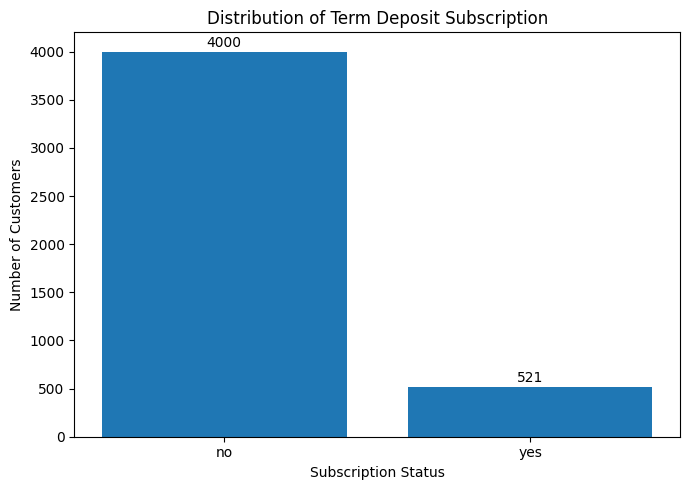

In [8]:

import matplotlib.pyplot as plt

subscription_counts = df['y'].value_counts().reindex(['no', 'yes'])

plt.figure(figsize=(7, 5))
plt.bar(subscription_counts.index, subscription_counts.values)

plt.title('Distribution of Term Deposit Subscription')
plt.xlabel('Subscription Status')
plt.ylabel('Number of Customers')

for i, count in enumerate(subscription_counts.values):
    plt.text(i, count + 50, str(count), ha='center')

plt.tight_layout()
plt.show()


job
retired          23.48
student          22.62
unknown          18.42
management       13.52
housemaid        12.50
admin.           12.13
self-employed    10.93
technician       10.81
unemployed       10.16
services          9.11
entrepreneur      8.93
blue-collar       7.29
Name: y, dtype: float64


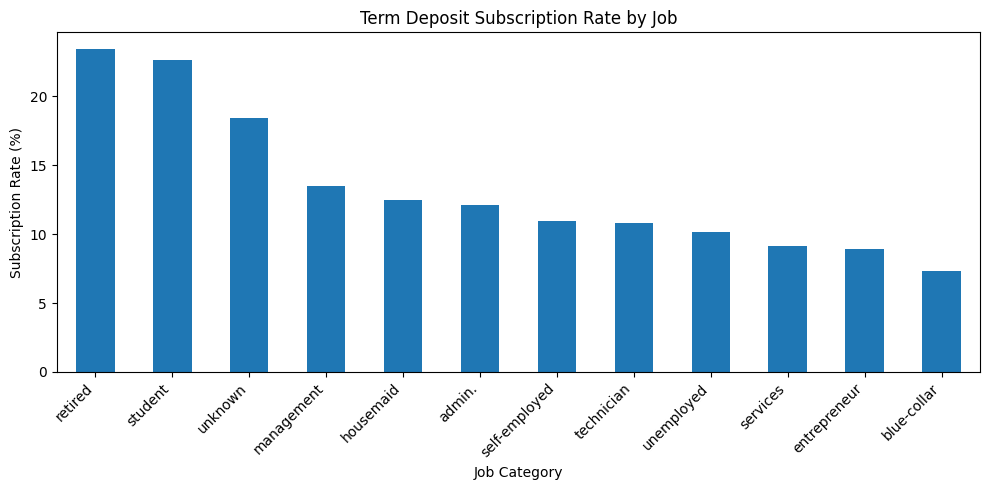

In [9]:

job_subscription_rate = (
    df.groupby('job')['y']
    .apply(lambda group: (group == 'yes').mean() * 100)
    .sort_values(ascending=False)
)

print(job_subscription_rate.round(2))

job_subscription_rate.plot(kind='bar', figsize=(10, 5))

plt.title('Term Deposit Subscription Rate by Job')
plt.xlabel('Job Category')
plt.ylabel('Subscription Rate (%)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [10]:

X = df.drop(columns=['y', 'duration'])
y = df['y'].map({'no': 0, 'yes': 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget values:")
print(y.value_counts())


Features shape: (4521, 15)
Target shape: (4521,)

Target values:
y
0    4000
1     521
Name: count, dtype: int64


In [11]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 3616
Testing records: 905


In [12]:

numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object']
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['age', 'balance', 'day', 'campaign', 'pdays', 'previous']

Categorical features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('numeric', numeric_pipeline, numeric_features),
    ('categorical', categorical_pipeline, categorical_features)
])

print("Data preparation is ready!")


Data preparation is ready!


In [14]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Define the four models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000, class_weight='balanced'
    ),
    'Decision Tree': DecisionTreeClassifier(
        random_state=42, class_weight='balanced'
    ),
    'KNN': KNeighborsClassifier(n_neighbors=5),
    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced'
    )
}

results = []
trained_models = {}

# Train and evaluate each model
for name, model in models.items():

    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    # Train the model
    pipeline.fit(X_train, y_train)

    # Predict subscription outcomes for test data
    predictions = pipeline.predict(X_test)

    # Calculate evaluation metrics
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(
            y_test, predictions, zero_division=0
        ),
        'Recall': recall_score(
            y_test, predictions, zero_division=0
        ),
        'F1-score': f1_score(
            y_test, predictions, zero_division=0
        )
    })

    # Save the trained model
    trained_models[name] = pipeline

# Create and display the comparison table
results_df = pd.DataFrame(results).round(3)
display(results_df)


,Model,Accuracy,Precision,Recall,F1-score
0,Logistic Regression,0.705,0.224,0.635,0.331
1,Decision Tree,0.799,0.221,0.298,0.254
2,KNN,0.876,0.278,0.048,0.082
3,Random Forest,0.893,0.684,0.125,0.211


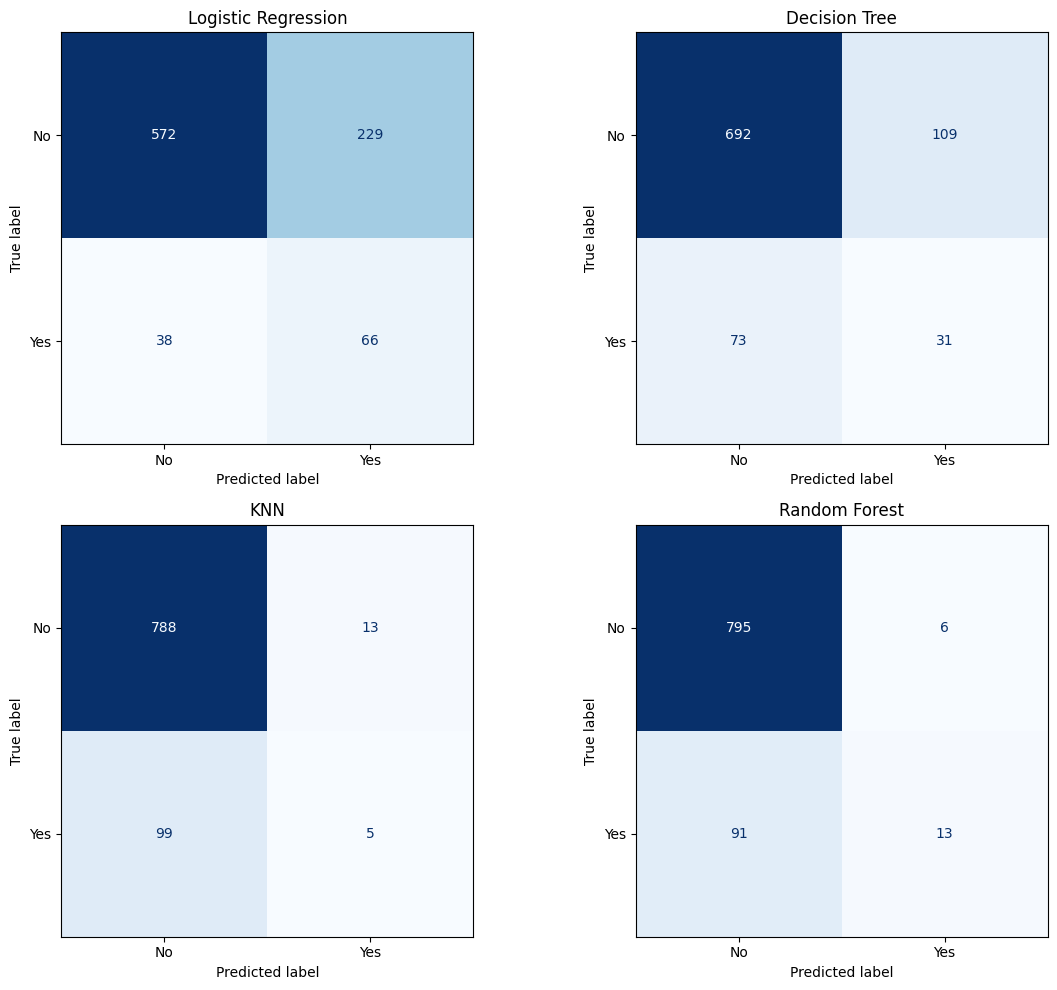

In [15]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

for ax, (name, pipeline) in zip(axes, trained_models.items()):

    predictions = pipeline.predict(X_test)

    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['No', 'Yes']
    )

    display_cm.plot(
        ax=ax,
        cmap='Blues',
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()


In [16]:

from sklearn.metrics import confusion_matrix

for name, pipeline in trained_models.items():
    predictions = pipeline.predict(X_test)
    cm = confusion_matrix(y_test, predictions, labels=[0, 1])

    print("\n", name)
    print(cm)



 Logistic Regression
[[572 229]
 [ 38  66]]

 Decision Tree
[[692 109]
 [ 73  31]]

 KNN
[[788  13]
 [ 99   5]]

 Random Forest
[[795   6]
 [ 91  13]]


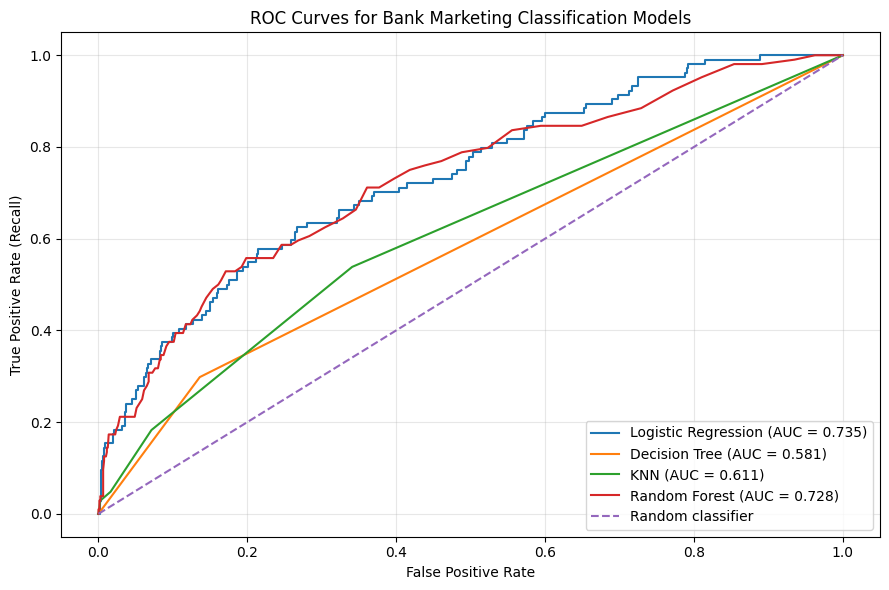

ROC-AUC scores:
Logistic Regression: 0.735
Decision Tree: 0.581
KNN: 0.611
Random Forest: 0.728


In [17]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

auc_results = {}

for name, pipeline in trained_models.items():

    # Get the probability of subscription (class 1)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    # Calculate ROC curve points
    fpr, tpr, thresholds = roc_curve(y_test, probabilities)

    # Calculate area under the ROC curve
    auc_value = roc_auc_score(y_test, probabilities)
    auc_results[name] = auc_value

    plt.plot(
        fpr, tpr,
        label=f'{name} (AUC = {auc_value:.3f})'
    )

# Reference line for random classification
plt.plot([0, 1], [0, 1], linestyle='--', label='Random classifier')

plt.title('ROC Curves for Bank Marketing Classification Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ROC-AUC scores:")
for name, score in auc_results.items():
    print(f"{name}: {score:.3f}")


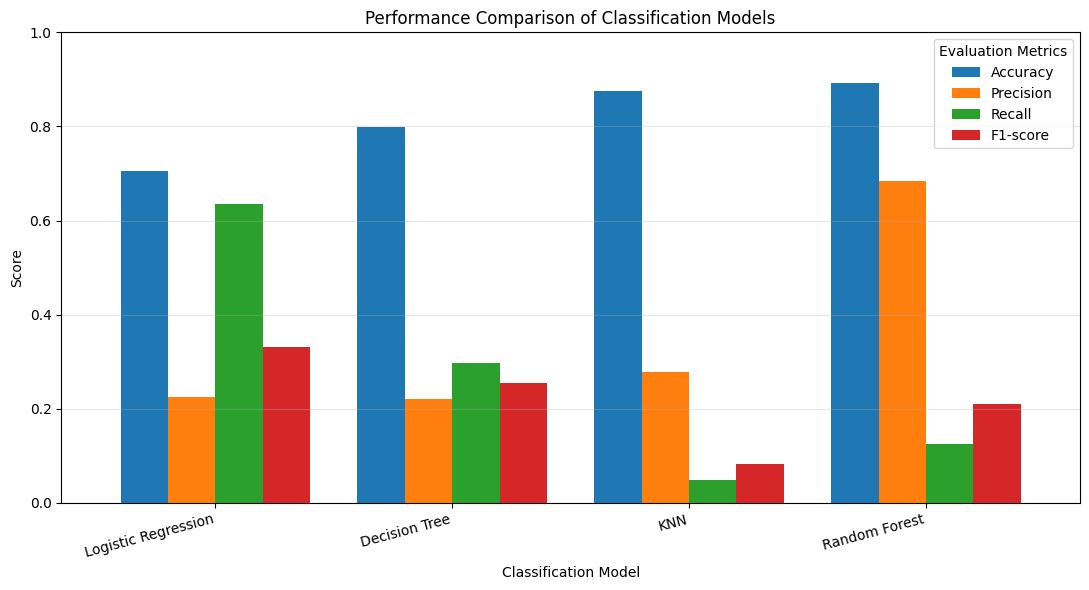

In [18]:

import matplotlib.pyplot as plt

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']

results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(11, 6),
    width=0.8
)

plt.title('Performance Comparison of Classification Models')
plt.xlabel('Classification Model')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15, ha='right')
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


### Task 4: Performance Comparison and Interpretation

The four classification algorithms were evaluated using accuracy, precision, recall, F1-score, confusion matrices, and ROC-AUC.

- **Logistic Regression:** Achieved a recall of 0.635, an F1-score of 0.331, and the highest ROC-AUC of 0.735. It identified 66 out of 104 actual subscribers in the test set.
- **Decision Tree:** Achieved an accuracy of 0.799 and a recall of 0.298. It identified fewer actual subscribers than Logistic Regression.
- **K-Nearest Neighbors (KNN):** Achieved an accuracy of 0.876 but a recall of only 0.048. It identified just 5 out of 104 actual subscribers.
- **Random Forest:** Achieved the highest accuracy (0.893) and precision (0.684), but its recall was 0.125. It identified 13 out of 104 actual subscribers.

**Conclusion:** Logistic Regression is the preferred model when the main objective is to identify more potential term-deposit subscribers. Random Forest has higher accuracy and precision, but misses more actual subscribers. Therefore, accuracy alone should not be used to select the best model. The final choice depends on the bank's campaign objectives and the cost of unnecessary calls.

Average values by subscription outcome:


,age,balance,campaign,previous
y,,,,
no,41.00,1403.21,2.86,0.47
yes,42.49,1571.96,2.27,1.09


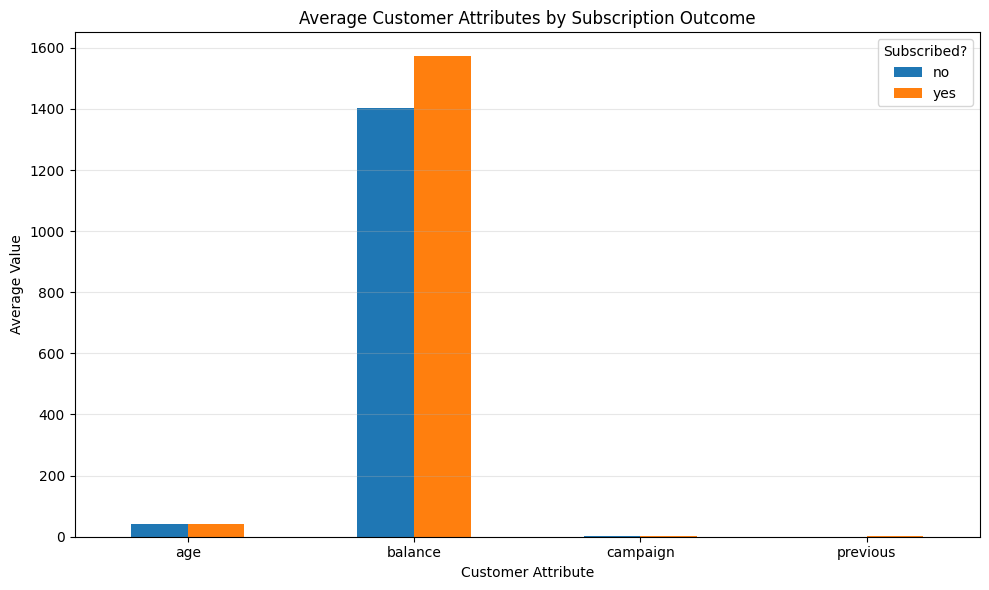

In [19]:

# Compare numerical attributes by subscription outcome

numeric_columns = [
    'age', 'balance', 'campaign', 'previous'
]

print("Average values by subscription outcome:")
display(
    df.groupby('y')[numeric_columns]
      .mean()
      .round(2)
)

# Visualize average values
df.groupby('y')[numeric_columns].mean().T.plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average Customer Attributes by Subscription Outcome')
plt.xlabel('Customer Attribute')
plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.legend(title='Subscribed?')
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [20]:

# Count missing values in each column
print("Missing values per column:")
print(df.isnull().sum())

# Count the literal 'unknown' values in each column
print("\nUnknown values per column:")
unknown_counts = (
    df.select_dtypes(include='object')
      .apply(lambda column: (column == 'unknown').sum())
)

print(unknown_counts[unknown_counts > 0])

# Count duplicate rows
print("\nDuplicate records:", df.duplicated().sum())

# Display subscription counts and percentages
print("\nTarget distribution:")
target_counts = df['y'].value_counts()
target_percentages = (
    df['y'].value_counts(normalize=True) * 100
)

target_summary = pd.DataFrame({
    'Count': target_counts,
    'Percentage': target_percentages.round(2)
})

display(target_summary)


Missing values per column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Unknown values per column:
job            38
education     187
contact      1324
poutcome     3705
dtype: int64

Duplicate records: 0

Target distribution:


,Count,Percentage
y,,
no,4000,88.48
yes,521,11.52


In [21]:
df.head(10)

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,30,unemployed,married,primary,no,1787,no,no,cellular,19,oct,79,1,-1,0,unknown,no
1,33,services,married,secondary,no,4789,yes,yes,cellular,11,may,220,1,339,4,failure,no
2,35,management,single,tertiary,no,1350,yes,no,cellular,16,apr,185,1,330,1,failure,no
3,30,management,married,tertiary,no,1476,yes,yes,unknown,3,jun,199,4,-1,0,unknown,no
4,59,blue-collar,married,secondary,no,0,yes,no,unknown,5,may,226,1,-1,0,unknown,no
5,35,management,single,tertiary,no,747,no,no,cellular,23,feb,141,2,176,3,failure,no
6,36,self-employed,married,tertiary,no,307,yes,no,cellular,14,may,341,1,330,2,other,no
7,39,technician,married,secondary,no,147,yes,no,cellular,6,may,151,2,-1,0,unknown,no
8,41,entrepreneur,married,tertiary,no,221,yes,no,unknown,14,may,57,2,-1,0,unknown,no
9,43,services,married,primary,no,-88,yes,yes,cellular,17,apr,313,1,147,2,failure,no


In [22]:
from sklearn.metrics import roc_auc_score

auc_results = {}

for name, pipeline in trained_models.items():
    probabilities = pipeline.predict_proba(X_test)[:, 1]
    auc_results[name] = roc_auc_score(y_test, probabilities)

final_results_df = results_df.copy()
final_results_df['ROC-AUC'] = final_results_df['Model'].map(auc_results)

display(final_results_df.round(3))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.705,0.224,0.635,0.331,0.735
1,Decision Tree,0.799,0.221,0.298,0.254,0.581
2,KNN,0.876,0.278,0.048,0.082,0.611
3,Random Forest,0.893,0.684,0.125,0.211,0.728


In [23]:

# Compare numerical values for subscribers and non-subscribers

numerical_comparison = df.groupby('y')[
    ['age', 'balance', 'campaign', 'previous']
].mean().round(2)

display(numerical_comparison)


,age,balance,campaign,previous
y,,,,
no,41.00,1403.21,2.86,0.47
yes,42.49,1571.96,2.27,1.09


### Three Observations from Exploratory Data Analysis

1. **Age:** Customers who subscribed had an average age of 42.49 years, compared with 41.00 years for customers who did not subscribe.

2. **Account balance:** Subscribers had a higher average account balance of 1571.96, compared with 1403.21 for non-subscribers.

3. **Campaign contacts:** Subscribers received fewer average contacts during the current campaign (2.27 compared with 2.86), but had more previous campaign contacts on average (1.09 compared with 0.47).

In [24]:

# Identify numerical, categorical, and target columns

target_column = 'y'

numerical_columns = df.select_dtypes(include=['number']).columns.tolist()
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

categorical_columns.remove(target_column)

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

print("\nTarget column:")
print(target_column)


Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']

Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

Target column:
y


## Task 5: Best Model Selection, Recommendations, and Limitations

### 1. Best Model Selection

Logistic Regression is selected as the preferred model when the main objective is to identify potential term-deposit subscribers. It achieved a recall of 0.635, an F1-score of 0.331, and a ROC-AUC of 0.735. It correctly identified 66 out of 104 actual subscribers in the test set.

Random Forest achieved the highest accuracy of 0.893 and precision of 0.684. However, its recall was only 0.125, meaning it identified just 13 out of 104 actual subscribers. Therefore, Logistic Regression is more suitable when identifying potential subscribers is the main priority.

### 2. Business Recommendations

1. The bank can use Logistic Regression predictions to prioritize customers for term-deposit marketing campaigns. The model should support marketing decisions rather than replace human judgment.
2. The bank should test different prediction thresholds and monitor campaign conversion rates, recall, precision, and contact costs to improve campaign efficiency.

### 3. Limitations

1. The dataset is imbalanced: only 11.52% of customers subscribed. Therefore, accuracy alone does not provide a complete picture of model performance.
2. The models were evaluated using one train-test split. Their performance may differ on new customer data, so further validation is needed before using the selected model in a real campaign.